## Preprocessing

Step 3 in the pipeline, where dataset is split into multiple different dataframes (detailed uses and reasons are given in `dataset_dictionary.md`).
Comments explain the code, detailed methodology is explained in the report.

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import  StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import  accuracy_score


df = pd.read_csv("../data/dataset.csv")

In [9]:
# Removing rows where HDI is NaN
df = df.drop(labels=df[df.Level.isna()].index) 

# Dropping country name (it does not serve as a predictor)
df = df.drop(columns=["Country"])
X = df.drop(columns =["Level"])
Y = df.Level

# Splitting data into test/train/validation (stratified split i.e roughly each class appears in the same amount in each split)
x_trv,x_te,y_trv,y_te = train_test_split(X,Y,random_state=10,stratify=Y,test_size=0.2)
x_tr,x_v,y_tr,y_v = train_test_split(x_trv,y_trv,random_state=10,stratify=y_trv,test_size=0.25)

print("Percentages of each class are-")
print(f"For train set\n{y_tr.value_counts()/len(y_tr)*100}\nFor validation set\n{y_v.value_counts()/len(y_v)*100}\
      \nFor test set\n{y_te.value_counts()/len(y_te)*100}")

Percentages of each class are-
For train set
Level
1.0    47.826087
2.0    38.260870
0.0    13.913043
Name: count, dtype: float64
For validation set
Level
1.0    48.717949
2.0    38.461538
0.0    12.820513
Name: count, dtype: float64      
For test set
Level
1.0    48.717949
2.0    38.461538
0.0    12.820513
Name: count, dtype: float64


As can be seen by the above output, the class count percentages (The class are 0,1,2 values of Level) are approximately the same across train,test and validation sets and have been split in a 60/20/20 ratio

## Defense for prefering median imputation over mean imputation

Compared to Mean imputation Median imputation is more resistant to outliers, for example, if the highest value in a category becomes orders of magnitude higher than the rest, the mean increases greatly but theres no change to the median. As such we went with median imputation (our data has many outliers)

But, it is possible that a value being missing is important information to predict the HDI, to account for this possibility, we are adding missing indicators, i.e for each numerical column, we are adding another column where each missing value gets a '1' and rest of the rows are '0'.

In [10]:
num_cols = x_tr.select_dtypes(include='number').columns
num_pipe = Pipeline([("imputer", SimpleImputer(strategy="median", add_indicator=True))])

cat_cols = x_tr.select_dtypes(exclude='number').columns
cat_pipe = Pipeline([("imputer", SimpleImputer(strategy="constant",fill_value="missing")),("encoder", OneHotEncoder(handle_unknown="ignore",sparse_output=False))])


In [11]:
total_pipe = Pipeline([
    ("imputer",ColumnTransformer([("num",num_pipe,num_cols),("cat",cat_pipe,cat_cols)],verbose_feature_names_out=False).set_output(transform="pandas")),
    ("scaling", ColumnTransformer([("num",StandardScaler(),num_cols)],remainder="passthrough",verbose_feature_names_out=False).set_output(transform="pandas"))])
#We only scale the original numerical columns, not missing indicators or other (0,1) columns

x_tr_clean= total_pipe.fit_transform(x_tr)
x_v_clean = total_pipe.transform(x_v)
x_te_clean = total_pipe.transform(x_te)
#We have now cleaned all the data

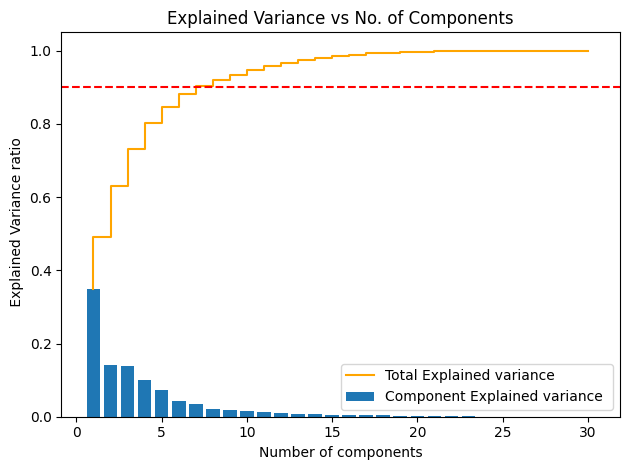

In [12]:
n = len(x_tr_clean.columns)  
pca = PCA(n_components=n)

components =pca.fit_transform(x_tr_clean)
explained_var = pca.explained_variance_ratio_
cumulative_var = np.cumsum(explained_var)

plt.bar(list(range(1,n+1)), explained_var,label = "Component Explained variance ")
plt.step(list(range(1,n+1)),cumulative_var, color = "orange",label="Total Explained variance")
plt.legend()
plt.xlabel("Number of components")
plt.title("Explained Variance vs No. of Components")
plt.ylabel(" Explained Variance ratio")
plt.axhline(y=0.9, color= "red", linestyle="--")
plt.tight_layout()
plt.savefig("../deliverables/report/figures/pca_variance.png", dpi=200)
plt.show()
plt.show()

In [13]:
principal_loading = pd.DataFrame()
for i in range(10):
 comp = np.abs(pca.components_[i])
 ind =np.argpartition(comp,-5)[-5:]
 ind = ind[np.argsort(-comp[ind])]
 principal_loading[f"PC{i+1}"] = x_tr_clean.columns[ind]

# Each column contains the top 5 features which contributed the most to that component
principal_loading 

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10
0,Individuals_using_the_Internet,GDP_Growth,Industry,Unemployment_total,Trade,Inflation_consumer_prices,Agriculture,Region_ECS,Infant_mortality,Individuals_using_the_Internet
1,Infant_mortality,Inflation_consumer_prices,Services,Agriculture,GDP_Growth,GDP_Growth,Access_to_electricity,Region_LCN,Individuals_using_the_Internet,Region_ECS
2,Agriculture,Industry,Inflation_consumer_prices,Infant_mortality,Unemployment_total,Agriculture,Unemployment_total,Infant_mortality,Region_ECS,Region_EAS
3,Access_to_electricity,Services,GDP_Growth,Inflation_consumer_prices,Access_to_electricity,Unemployment_total,Services,Access_to_electricity,Region_LCN,Access_to_electricity
4,Services,Trade,Individuals_using_the_Internet,GDP_Growth,Inflation_consumer_prices,Services,Industry,Agriculture,Unemployment_total,missingindicator_Inflation_consumer_prices


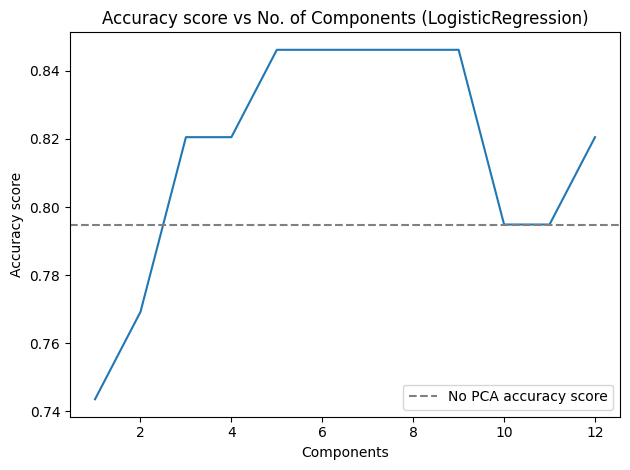

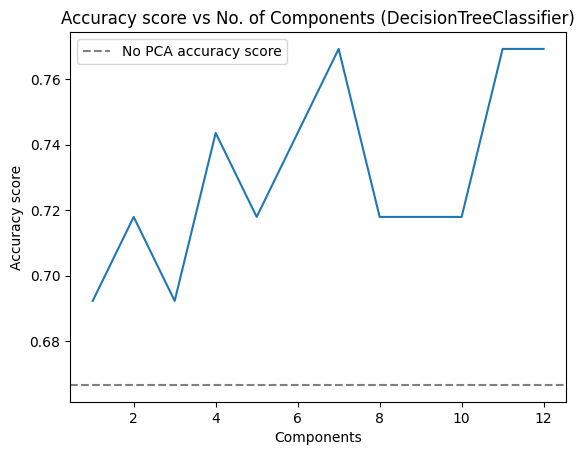

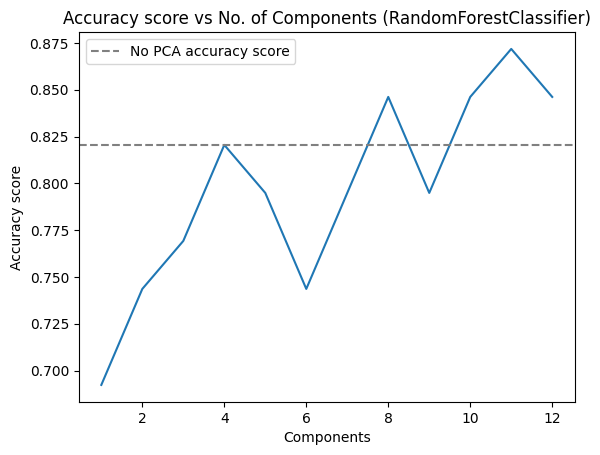

In [15]:
pca_data = pca.transform(x_v_clean)

# Random states of a model have been fixed so as to get reproducible results
for model in [LogisticRegression(random_state = 10), DecisionTreeClassifier(random_state = 10), RandomForestClassifier(random_state = 10)]:
     accuracies = []
     model.fit(x_tr_clean,y_tr)
     y_no_pca = model.predict(x_v_clean)
     for i in range(1,13): # We dont check PCA with a high number of components since the point of PCA is to reduce components
      model.fit(components[:,0:i],y_tr)
      y_pca = model.predict(pca_data[:,0:i])
      accuracies.append(accuracy_score(y_v,y_pca))

     plt.plot(list(range(1,13)),accuracies)
     plt.xlabel("Components")
     plt.ylabel("Accuracy score")
     plt.axhline(accuracy_score(y_v,y_no_pca), color="grey",linestyle = "--",label="No PCA accuracy score")
     plt.legend()
     name = model.__class__.__name__
     plt.title(f"Accuracy score vs No. of Components ({name})")
     if isinstance(model, LogisticRegression):
         plt.tight_layout()
         plt.savefig("../deliverables/report/figures/pca_accuracy.png", dpi=200)
     plt.show()
